<a href="https://colab.research.google.com/github/zk025815-beep/ML-Foundations-From-Scratch/blob/main/K_Means_Clustering_in_Pure_NumPy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Converged at iteration 4!
Final WCSS (Inertia): 271.56


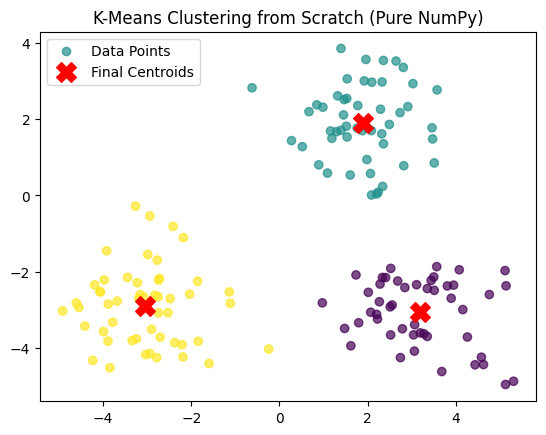

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate synthetic 2D data with 3 natural clusters (No labels used for training!)
np.random.seed(42)
c1 = np.random.randn(50, 2) + np.array([2, 2])
c2 = np.random.randn(50, 2) + np.array([-3, -3])
c3 = np.random.randn(50, 2) + np.array([3, -3])
X = np.vstack([c1, c2, c3]) # Shape: (150, 2)

# 2. Initialize K=3 random centroids from existing data points
K = 3
random_indices = np.random.choice(X.shape[0], K, replace=False)
centroids = X[random_indices] # Shape: (3, 2)

epochs = 10

# 3. K-Means Loop
for i in range(epochs):
    # Step A: Compute Euclidean distance from each point (150, 1, 2) to each centroid (1, 3, 2)
    # Distance formula: sqrt(sum((x - mu)^2))
    distances = np.sqrt(np.sum((X[:, np.newaxis] - centroids) ** 2, axis=2)) # Shape: (150, 3)

    # Step B: Assign each point to the closest centroid index (0, 1, or 2)
    labels = np.argmin(distances, axis=1) # Shape: (150,)

    # Step C: Update centroids by taking the mean of points in each cluster
    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(K)])

    # Check convergence (if centroids stopped moving, break early)
    if np.allclose(centroids, new_centroids):
        print(f"Converged at iteration {i+1}!")
        break
    centroids = new_centroids

# 4. Compute Final Inertia (Within-Cluster Sum of Squares / WCSS)
inertia = sum(np.sum((X[labels == k] - centroids[k]) ** 2) for k in range(K))
print(f"Final WCSS (Inertia): {inertia:.2f}")

# Plot Clustered Data and Centroids
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', alpha=0.7, label='Data Points')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=200, label='Final Centroids')
plt.title("K-Means Clustering from Scratch (Pure NumPy)")
plt.legend()
plt.show()